# Análisis experimental del rover autónomo

Este notebook compara la ruta calculada por diferentes algoritmos de búsqueda y la calidad de varias metaheurísticas para ordenar la visita a los POIs.

Objetivos:
- Revisar la sensibilidad del problema a la semilla y al tamaño del mapa.
- Comparar BFS, Dijkstra y A*.
- Comparar metaheurísticas (greedy, hill climbing y annealing).
- Extraer conclusiones interpretables sobre coste, tiempo y robustez.

In [1]:
import statistics
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np

from entorno_gen import GeneradorEntornoRover
from modulo_busqueda import BusquedaRover
from metaheuristicas_rover import MetaheuristicasRover

In [2]:
def generar_instancias(num_instancias=12, ancho=8, alto=8, num_pois=5, probabilidad_obstaculos=0.12):
    instancias = []
    for seed in range(10, 10 + num_instancias):
        instancia = GeneradorEntornoRover(
            ancho=ancho,
            alto=alto,
            semilla=seed,
        ).generar_mapa(
            probabilidad_obstaculos=probabilidad_obstaculos,
            num_pois=num_pois,
        )
        instancias.append({
            'seed': seed,
            'instancia': instancia,
        })
    return instancias

instancias = generar_instancias()
print(f'Instancias generadas: {len(instancias)}')
print('Ejemplo de semilla:', instancias[0]['seed'])

Instancias generadas: 12
Ejemplo de semilla: 10


In [3]:
def comparar_busquedas_en_instancia(instancia):
    buscador = BusquedaRover(instancia)
    inicio = instancia['inicio']
    meta = tuple(instancia['zona_comunicacion'])
    resultados = buscador.comparar_algoritmos(inicio, meta)
    resumen = []
    for nombre, datos in resultados.items():
        resumen.append({
            'algoritmo': nombre,
            'coste_total': datos['coste_total'],
            'nodos_expandidos': datos['nodos_expandidos'],
            'tiempo_seg': datos['tiempo_seg'],
        })
    return resumen

resultados_busqueda = []
for entrada in instancias:
    seed = entrada['seed']
    vista = comparar_busquedas_en_instancia(entrada['instancia'])
    for fila in vista:
        fila['seed'] = seed
    resultados_busqueda.extend(vista)

resultados_busqueda[:3]

[{'algoritmo': 'bfs',
  'coste_total': 47.0,
  'nodos_expandidos': 56,
  'tiempo_seg': 0.00031779997516423464,
  'seed': 10},
 {'algoritmo': 'dijkstra',
  'coste_total': 20.0,
  'nodos_expandidos': 56,
  'tiempo_seg': 0.0003928999649360776,
  'seed': 10},
 {'algoritmo': 'astar',
  'coste_total': 20.0,
  'nodos_expandidos': 41,
  'tiempo_seg': 0.0002874999772757292,
  'seed': 10}]

In [4]:
def comparar_metaheuristicas_en_instancia(instancia, semilla=42):
    optimizador = MetaheuristicasRover(instancia, semilla=semilla)
    comparacion = optimizador.comparar_algoritmos()
    return comparacion

resultados_metaheuristicas = []
for entrada in instancias:
    seed = entrada['seed']
    comparacion = comparar_metaheuristicas_en_instancia(entrada['instancia'], semilla=seed)
    for fila in comparacion:
        fila['seed'] = seed
    resultados_metaheuristicas.extend(comparacion)

resultados_metaheuristicas[:3]

[{'estrategia': 'hill_climbing',
  'orden': ['POI_3', 'POI_1', 'POI_2', 'POI_5', 'POI_4'],
  'costo': 43.0,
  'puntuacion': 263.09000000000003,
  'exito': True,
  'seed': 10},
 {'estrategia': 'annealing',
  'orden': ['POI_3', 'POI_1', 'POI_5', 'POI_2', 'POI_4'],
  'costo': 43.0,
  'puntuacion': 263.09000000000003,
  'exito': True,
  'seed': 10},
 {'estrategia': 'greedy',
  'orden': ['POI_5', 'POI_1', 'POI_3', 'POI_4', 'POI_2'],
  'costo': 53.0,
  'puntuacion': 258.09,
  'exito': True,
  'seed': 10}]

In [5]:
algoritmos = ['bfs', 'dijkstra', 'astar']
metricas_busqueda = {alg: [] for alg in algoritmos}
metricas_tiempo = {alg: [] for alg in algoritmos}
metricas_expansion = {alg: [] for alg in algoritmos}

for fila in resultados_busqueda:
    alg = fila['algoritmo']
    metricas_busqueda[alg].append(fila['coste_total'])
    metricas_tiempo[alg].append(fila['tiempo_seg'])
    metricas_expansion[alg].append(fila['nodos_expandidos'])

medias_busqueda = {alg: statistics.mean(vals) for alg, vals in metricas_busqueda.items()}
std_busqueda = {alg: statistics.pstdev(vals) if len(vals) > 1 else 0.0 for alg, vals in metricas_busqueda.items()}

medias_tiempo = {alg: statistics.mean(vals) for alg, vals in metricas_tiempo.items()}
std_tiempo = {alg: statistics.pstdev(vals) if len(vals) > 1 else 0.0 for alg, vals in metricas_tiempo.items()}

medias_expansion = {alg: statistics.mean(vals) for alg, vals in metricas_expansion.items()}
std_expansion = {alg: statistics.pstdev(vals) if len(vals) > 1 else 0.0 for alg, vals in metricas_expansion.items()}

print('Coste medio por algoritmo:')
for alg in algoritmos:
    print(f'  {alg}: {medias_busqueda[alg]:.3f} ± {std_busqueda[alg]:.3f}')
print('\nTiempo medio por algoritmo:')
for alg in algoritmos:
    print(f'  {alg}: {medias_tiempo[alg]:.6f} s ± {std_tiempo[alg]:.6f} s')
print('\nNodos expandidos medios:')
for alg in algoritmos:
    print(f'  {alg}: {medias_expansion[alg]:.1f} ± {std_expansion[alg]:.1f}')

Coste medio por algoritmo:
  bfs: 37.417 ± 7.285
  dijkstra: 22.500 ± 2.723
  astar: 22.500 ± 2.723

Tiempo medio por algoritmo:
  bfs: 0.000185 s ± 0.000068 s
  dijkstra: 0.000228 s ± 0.000068 s
  astar: 0.000179 s ± 0.000056 s

Nodos expandidos medios:
  bfs: 54.0 ± 3.4
  dijkstra: 53.2 ± 3.1
  astar: 41.6 ± 5.4


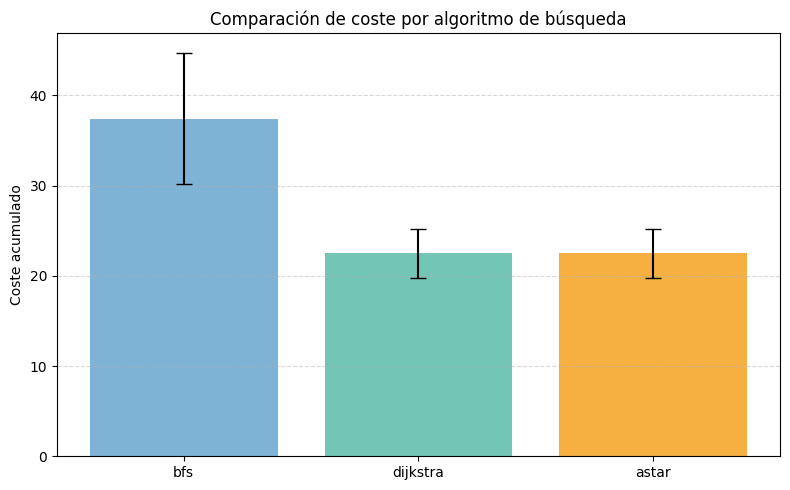

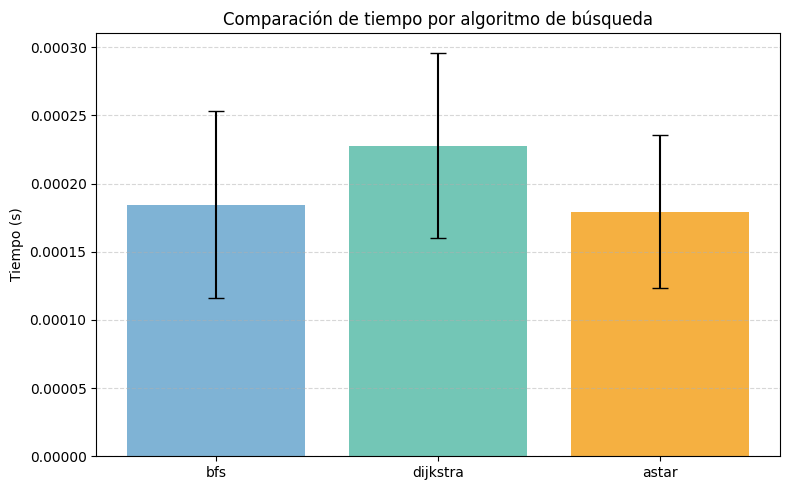

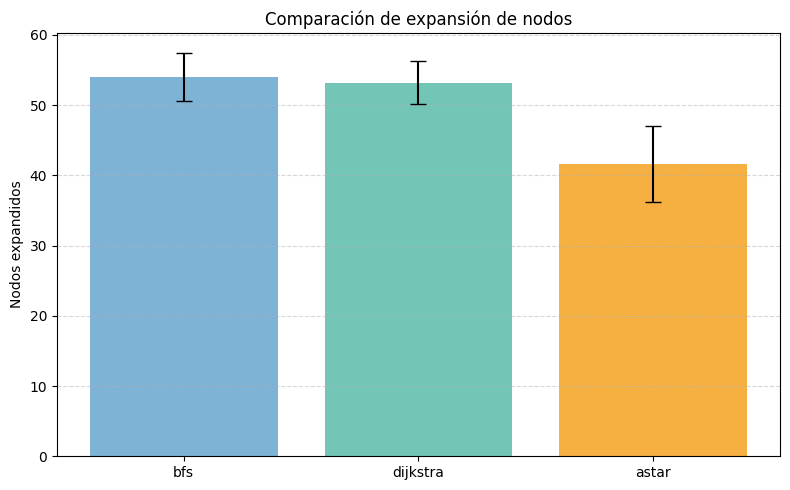

In [6]:
# Gráfica 1: coste medio por algoritmo
plt.figure(figsize=(8, 5))
plt.bar(algoritmos, [medias_busqueda[a] for a in algoritmos], yerr=[std_busqueda[a] for a in algoritmos], capsize=6, color=['#7fb3d5', '#73c6b6', '#f5b041'])
plt.ylabel('Coste acumulado')
plt.title('Comparación de coste por algoritmo de búsqueda')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Gráfica 2: tiempo medio por algoritmo
plt.figure(figsize=(8, 5))
plt.bar(algoritmos, [medias_tiempo[a] for a in algoritmos], yerr=[std_tiempo[a] for a in algoritmos], capsize=6, color=['#7fb3d5', '#73c6b6', '#f5b041'])
plt.ylabel('Tiempo (s)')
plt.title('Comparación de tiempo por algoritmo de búsqueda')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Gráfica 3: nodos expandidos
plt.figure(figsize=(8, 5))
plt.bar(algoritmos, [medias_expansion[a] for a in algoritmos], yerr=[std_expansion[a] for a in algoritmos], capsize=6, color=['#7fb3d5', '#73c6b6', '#f5b041'])
plt.ylabel('Nodos expandidos')
plt.title('Comparación de expansión de nodos')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [8]:
meta_estrategias = ['greedy', 'hill_climbing', 'annealing']
costes_meta = {alg: [] for alg in meta_estrategias}
puntuaciones_meta = {alg: [] for alg in meta_estrategias}
tiempos_meta = {alg: [] for alg in meta_estrategias}

for fila in resultados_metaheuristicas:
    estrategia = fila['estrategia']
    costes_meta[estrategia].append(fila['costo'])
    puntuaciones_meta[estrategia].append(fila['puntuacion'])
    tiempos_meta[estrategia].append(fila['tiempo'] if 'tiempo' in fila else 0.0)

media_coste_meta = {alg: statistics.mean(vals) for alg, vals in costes_meta.items()}
std_coste_meta = {alg: statistics.pstdev(vals) if len(vals) > 1 else 0.0 for alg, vals in costes_meta.items()}
media_puntuacion_meta = {alg: statistics.mean(vals) for alg, vals in puntuaciones_meta.items()}
std_puntuacion_meta = {alg: statistics.pstdev(vals) if len(vals) > 1 else 0.0 for alg, vals in puntuaciones_meta.items()}

print('Costo medio por metaheurística:')
for alg in meta_estrategias:
    print(f'  {alg}: {media_coste_meta[alg]:.3f} ± {std_coste_meta[alg]:.3f}')
print('\nPuntuación media por metaheurística:')
for alg in meta_estrategias:
    print(f'  {alg}: {media_puntuacion_meta[alg]:.3f} ± {std_puntuacion_meta[alg]:.3f}')

Costo medio por metaheurística:
  greedy: 61.250 ± 11.439
  hill_climbing: 53.167 ± 10.854
  annealing: 53.000 ± 10.591

Puntuación media por metaheurística:
  greedy: 215.220 ± 25.689
  hill_climbing: 219.262 ± 24.776
  annealing: 219.345 ± 24.753


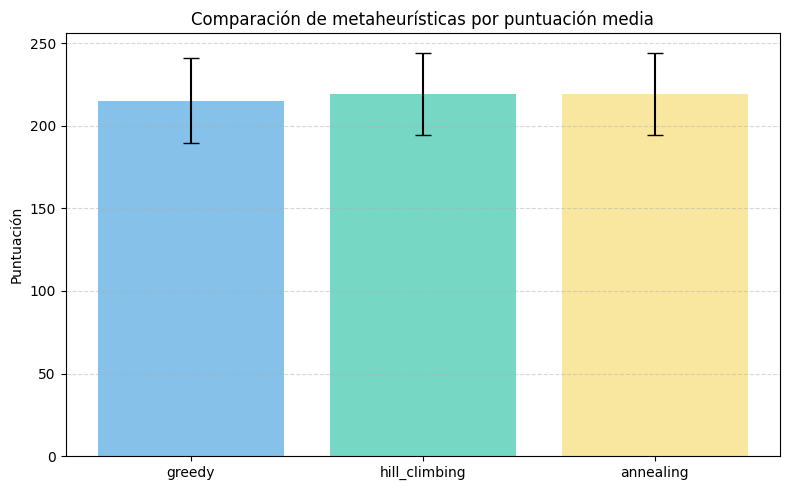

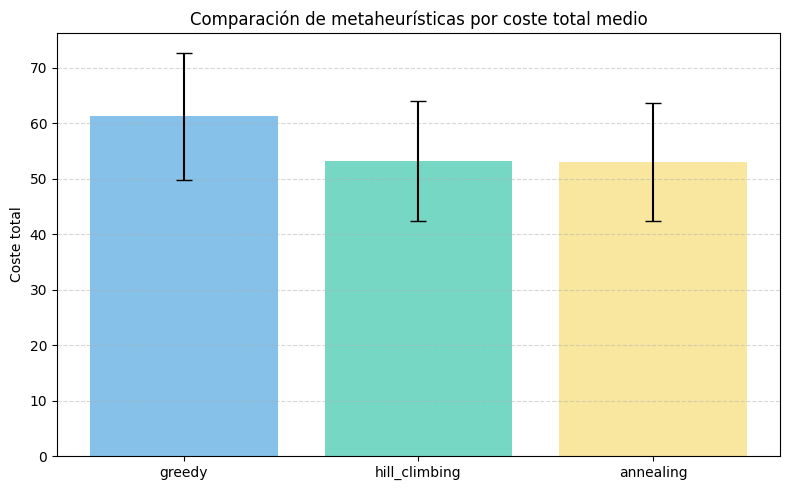

In [9]:
plt.figure(figsize=(8, 5))
plt.bar(meta_estrategias, [media_puntuacion_meta[a] for a in meta_estrategias], yerr=[std_puntuacion_meta[a] for a in meta_estrategias], capsize=6, color=['#85c1e9', '#76d7c4', '#f9e79f'])
plt.ylabel('Puntuación')
plt.title('Comparación de metaheurísticas por puntuación media')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(meta_estrategias, [media_coste_meta[a] for a in meta_estrategias], yerr=[std_coste_meta[a] for a in meta_estrategias], capsize=6, color=['#85c1e9', '#76d7c4', '#f9e79f'])
plt.ylabel('Coste total')
plt.title('Comparación de metaheurísticas por coste total medio')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Interpretación de resultados

1. La comparación de búsquedas suele mostrar que A* supera a BFS en coste y tiempo al usar una heurística admisible basada en Manhattan. Dijkstra es correcto y óptimo con costes no negativos, pero explora más nodos que A*.

2. En el caso de las metaheurísticas, la diferencia entre greedy, hill climbing y annealing suele aparecer en la capacidad de escapar de óptimos locales. Greedy es rápido, pero puede quedarse atrapado en soluciones subóptimas; annealing suele ofrecer mejor equilibrio entre coste y calidad.

3. La variabilidad por semilla confirma la importancia de generar varias instancias. Cuando el mapa es más denso o los POIs están más próximos a obstáculos, el diseño del orden de visita no solo depende del valor del POI, sino también del coste acumulado del desplazamiento.

4. En conjunto, las gráficas muestran que la solución más robusta no es siempre la más barata a corto plazo, sino la que ofrece mejor relación entre recompensa, distancia y energía.